# INT8-Quantized 1D-CNN versus a Spiking Neural Network for ECG Arrhythmia Detection on MIT-BIH

**Author:** A S M SAYEM
**Affiliation:** East West University

---

### Intention

Edge deployment of cardiac arrhythmia classifiers requires models that are simultaneously accurate, compact, and energy-efficient. This notebook presents a small-scale, reproducible comparison of three model families trained on the MIT-BIH Arrhythmia Database (pre-segmented mitbih_train.csv / mitbih_test.csv release): (i) a full-precision (FP32) 1D convolutional neural network, (ii) its INT8 post-training quantized counterpart, and (iii) a spiking neural network (SNN) trained with backpropagation-through-time (BPTT) using the snnTorch library. Beyond a static comparison, this study additionally characterizes the SNN's accuracy-energy trade-off across inference timesteps (T = 2 to 30, no retraining required) to identify the minimum temporal resolution at which spiking inference remains competitive with the dense baseline. All models are evaluated on an untouched test split for accuracy, precision/recall/F1 on the arrhythmia class, ROC-AUC, parameter count, on-disk model size, and measured CPU inference latency. Energy consumption is NOT measured on hardware; an operation-count-based estimate is derived instead from published per-operation energy figures (Horowitz, ISSCC 2014) and reported as an explicit estimate with stated assumptions.

### Contents
1. Introduction
2. Dataset and Preprocessing
3. Methodology
   3.1 Baseline FP32 CNN
   3.2 INT8 Post-Training Quantization
   3.3 Spiking Neural Network (snnTorch)
   3.4 Energy Estimation Methodology
4. Experimental Setup
5. Results
   5.1 Classification Performance
   5.2 Efficiency Metrics
   5.3 ROC Comparison
   5.4 Spiking Activity Analysis
   5.5 Energy Estimates
   5.6 Accuracy-Energy Trade-off Across Timesteps
   5.7 Spike Raster: Normal vs Arrhythmic Beats
6. Discussion
7. Limitations
8. Conclusion and Future Work
References

## 1. Introduction

Wearable and implantable cardiac monitoring devices are constrained by battery capacity, making model efficiency as important as predictive accuracy. Two efficiency-oriented paradigms are commonly proposed for such constraints: (a) quantization of conventional artificial neural networks (ANNs) to reduce numerical precision, and (b) spiking neural networks (SNNs), which communicate via sparse binary events and are theoretically compatible with low-power, event-driven neuromorphic hardware.

This notebook implements a controlled comparison of these two paradigms against a standard FP32 baseline, on the binary task of distinguishing normal versus arrhythmic heartbeats using the MIT-BIH Arrhythmia Database. Beyond a single-point comparison, it also investigates how few timesteps the SNN can use before accuracy degrades, and what energy savings reduced temporal resolution yields. Every reported number is computed from code in this notebook.

## 2. Dataset and Preprocessing

The dataset consists of two pre-segmented CSV files derived from the MIT-BIH Arrhythmia Database: mitbih_train.csv and mitbih_test.csv. Each row represents one heartbeat segment; the final column is the annotation label (0 = normal, 1-4 = four arrhythmia sub-types). For this study the task is collapsed to binary classification (0 = normal, 1 = arrhythmia).

mitbih_train.csv is used exclusively for model fitting, with a stratified 10% split held out for validation. mitbih_test.csv is used exactly once, for final evaluation. No synthetic data augmentation is applied; class imbalance is handled via class-weighted loss. Random seeds are fixed throughout.

IMPORTANT CAVEAT: the released CSV files contain no patient/record identifier. The train/test split operates at the beat level, not the patient level. This may overstate generalization performance. This is a primary limitation (see Section 7).

In [19]:
!pip install snntorch -q

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
os.makedirs("/content/drive/MyDrive/ecg_project/figures", exist_ok=True)
os.makedirs("/content/drive/MyDrive/ecg_project/artifacts", exist_ok=True)

In [3]:
import os, sys, time, random, copy, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, roc_auc_score, roc_curve)
import matplotlib.pyplot as plt
import matplotlib as mpl

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mpl.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

os.makedirs("figures", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)

print(f"Python        : {sys.version.split()[0]}")
print(f"PyTorch       : {torch.__version__}")
print(f"NumPy         : {np.__version__}")
print(f"Pandas        : {pd.__version__}")
print(f"Device in use : {device}")

Python        : 3.13.16
PyTorch       : 2.11.0+cu130
NumPy         : 2.1.3
Pandas        : 2.2.3
Device in use : cuda


In [11]:
try:
    import snntorch as snn
    from snntorch import surrogate
    print(f"snnTorch      : {snn.__version__}")
except ImportError:
    raise ImportError(
        "snnTorch not found. Install it with `pip install snntorch` "
        "before continuing - the SNN section depends on it."
    )

snnTorch      : 1.0.0


## 2.1 Data Loading

Loads the two CSV files from the working directory. If a Colab environment is detected, an upload prompt is offered; otherwise the notebook expects the files to already be present alongside it.

In [7]:
import os
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_FOLDER = "/content/drive/MyDrive/ecg_project"

DATA_FILES = {
    "mitbih_train.csv": os.path.join(DRIVE_FOLDER, "mitbih_train.csv"),
    "mitbih_test.csv": os.path.join(DRIVE_FOLDER, "mitbih_test.csv"),
}

missing = [name for name, path in DATA_FILES.items() if not os.path.exists(path)]

if missing:
    try:
        from google.colab import files
        print(f"Missing files in Drive: {missing}. Opening Colab upload dialog.")
        files.upload()
        DATA_FILES = {name: name for name in DATA_FILES}
    except ImportError:
        raise FileNotFoundError(f"Missing required file(s): {missing}.")

train_df = pd.read_csv(DATA_FILES["mitbih_train.csv"], header=None)
test_df  = pd.read_csv(DATA_FILES["mitbih_test.csv"], header=None)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train shape: (87554, 188)
Test shape : (21892, 188)


In [8]:
print("Raw multi-class label distribution - train:")
print(train_df.iloc[:, -1].value_counts().sort_index())
print("\nRaw multi-class label distribution - test:")
print(test_df.iloc[:, -1].value_counts().sort_index())

Raw multi-class label distribution - train:
187
0.0    72471
1.0     2223
2.0     5788
3.0      641
4.0     6431
Name: count, dtype: int64

Raw multi-class label distribution - test:
187
0.0    18118
1.0      556
2.0     1448
3.0      162
4.0     1608
Name: count, dtype: int64


In [9]:
N_FEATURES = train_df.shape[1] - 1

X_train_full = train_df.iloc[:, :N_FEATURES].values.astype(np.float32)
y_train_full = (train_df.iloc[:, -1].values.astype(int) != 0).astype(int)
X_test = test_df.iloc[:, :N_FEATURES].values.astype(np.float32)
y_test = (test_df.iloc[:, -1].values.astype(int) != 0).astype(int)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10,
    stratify=y_train_full, random_state=SEED
)

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print("Binary class balance - train:", pd.Series(y_train).value_counts(normalize=True).round(3).to_dict())
print("Binary class balance - val  :", pd.Series(y_val).value_counts(normalize=True).round(3).to_dict())
print("Binary class balance - test :", pd.Series(y_test).value_counts(normalize=True).round(3).to_dict())

from collections import Counter
counts = Counter(y_train)
total = sum(counts.values())
class_weights = torch.tensor(
    [total/(2*counts[0]), total/(2*counts[1])], dtype=torch.float32
).to(device)
print("\nClass weights (for weighted cross-entropy):", class_weights.cpu().numpy())

Train: (78798, 187) | Val: (8756, 187) | Test: (21892, 187)
Binary class balance - train: {0: 0.828, 1: 0.172}
Binary class balance - val  : {0: 0.828, 1: 0.172}
Binary class balance - test : {0: 0.828, 1: 0.172}

Class weights (for weighted cross-entropy): [0.6040661 2.9023204]


In [10]:
def to_tensor_dataset(X, y):
    X_t = torch.tensor(X, dtype=torch.float32).unsqueeze(1)
    y_t = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_t, y_t)

train_ds = to_tensor_dataset(X_train, y_train)
val_ds   = to_tensor_dataset(X_val, y_val)
test_ds  = to_tensor_dataset(X_test, y_test)

BATCH_SIZE = 128
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

SIGNAL_LEN = X_train.shape[1]

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Signal length per beat:", SIGNAL_LEN)

Signal length per beat: 187


## 3. Methodology

### 3.1 Baseline FP32 CNN

A compact 1D-CNN is used as the full-precision baseline: two convolutional blocks (Conv1d -> ReLU -> MaxPool1d) followed by two fully connected layers. Training uses Adam, class-weighted cross-entropy loss, and early stopping on validation loss.

In [11]:
class ECG_CNN(nn.Module):
    """Baseline FP32 1D-CNN: 2 conv blocks + 2 FC layers."""
    def __init__(self, signal_len: int, n_classes: int = 2):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 16, kernel_size=7, padding=3)
        self.pool1 = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(16, 32, kernel_size=5, padding=2)
        self.pool2 = nn.MaxPool1d(2)
        self.relu = nn.ReLU()
        flat_len = signal_len // 4
        self.fc1 = nn.Linear(32 * flat_len, 64)
        self.fc2 = nn.Linear(64, n_classes)

    def forward(self, x):
        x = self.pool1(self.relu(self.conv1(x)))
        x = self.pool2(self.relu(self.conv2(x)))
        x = x.flatten(1)
        x = self.relu(self.fc1(x))
        return self.fc2(x)

cnn_model = ECG_CNN(SIGNAL_LEN).to(device)
print(cnn_model)
print("\nFP32 CNN trainable parameters:", count_parameters(cnn_model))

ECG_CNN(
  (conv1): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=1472, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
)

FP32 CNN trainable parameters: 97122


In [12]:
def train_model(model, train_loader, val_loader, class_weights,
                 max_epochs=30, patience=5, lr=1e-3, model_name="model"):
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_val_loss, best_state, bad_epochs = float("inf"), None, 0
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(max_epochs):
        model.train()
        run_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * xb.size(0)
        train_loss = run_loss / len(train_loader.dataset)

        model.eval()
        val_loss, correct = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                val_loss += criterion(out, yb).item() * xb.size(0)
                correct += (out.argmax(1) == yb).sum().item()
        val_loss /= len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"[{model_name}] epoch {epoch+1:02d} | "
              f"train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"Early stopping triggered at epoch {epoch+1}.")
                break

    model.load_state_dict(best_state)
    return model, history

cnn_model, cnn_history = train_model(
    cnn_model, train_loader, val_loader, class_weights, model_name="FP32-CNN"
)

[FP32-CNN] epoch 01 | train_loss=0.3093  val_loss=0.2195  val_acc=0.9070
[FP32-CNN] epoch 02 | train_loss=0.1995  val_loss=0.1612  val_acc=0.9509
[FP32-CNN] epoch 03 | train_loss=0.1685  val_loss=0.1425  val_acc=0.9481
[FP32-CNN] epoch 04 | train_loss=0.1486  val_loss=0.1348  val_acc=0.9663
[FP32-CNN] epoch 05 | train_loss=0.1357  val_loss=0.1321  val_acc=0.9516
[FP32-CNN] epoch 06 | train_loss=0.1271  val_loss=0.1104  val_acc=0.9582
[FP32-CNN] epoch 07 | train_loss=0.1163  val_loss=0.1111  val_acc=0.9696
[FP32-CNN] epoch 08 | train_loss=0.1109  val_loss=0.1009  val_acc=0.9661
[FP32-CNN] epoch 09 | train_loss=0.1006  val_loss=0.0945  val_acc=0.9694
[FP32-CNN] epoch 10 | train_loss=0.0943  val_loss=0.0930  val_acc=0.9700
[FP32-CNN] epoch 11 | train_loss=0.0882  val_loss=0.0929  val_acc=0.9774
[FP32-CNN] epoch 12 | train_loss=0.0827  val_loss=0.0990  val_acc=0.9790
[FP32-CNN] epoch 13 | train_loss=0.0787  val_loss=0.0850  val_acc=0.9709
[FP32-CNN] epoch 14 | train_loss=0.0752  val_loss=0

In [13]:
def evaluate_model(model, loader, dev=device, is_snn=False, snn_forward_fn=None):
    model.eval()
    preds, labels, scores = [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(dev)
            if is_snn:
                logits, _ = snn_forward_fn(model, xb)
            else:
                logits = model(xb)
            probs = F.softmax(logits, dim=1)
            preds.extend(probs.argmax(1).cpu().numpy())
            labels.extend(yb.numpy())
            scores.extend(probs[:, 1].cpu().numpy())

    preds, labels, scores = map(np.array, (preds, labels, scores))
    metrics = {
        "accuracy": accuracy_score(labels, preds),
        "precision_arrhythmia": precision_score(labels, preds, pos_label=1, zero_division=0),
        "recall_arrhythmia": recall_score(labels, preds, pos_label=1, zero_division=0),
        "f1_arrhythmia": f1_score(labels, preds, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(labels, scores),
    }
    cm = confusion_matrix(labels, preds)
    return metrics, cm, labels, preds, scores


def measure_latency_cpu(model, sample_tensor, n_warmup=20, n_runs=200,
                         is_snn=False, snn_forward_fn=None):
    m = copy.deepcopy(model).to("cpu").eval()
    x = sample_tensor[:1].to("cpu")
    with torch.no_grad():
        for _ in range(n_warmup):
            snn_forward_fn(m, x) if is_snn else m(x)
        times = []
        for _ in range(n_runs):
            t0 = time.perf_counter()
            snn_forward_fn(m, x) if is_snn else m(x)
            times.append(time.perf_counter() - t0)
    return float(np.mean(times) * 1000), float(np.std(times) * 1000)


def get_model_size_kb(model, path):
    torch.save(model, path)
    return os.path.getsize(path) / 1024.0

In [14]:
cnn_metrics, cnn_cm, cnn_labels, cnn_preds, cnn_scores = evaluate_model(cnn_model, test_loader)
cnn_latency_mean, cnn_latency_std = measure_latency_cpu(cnn_model, next(iter(test_loader))[0])
cnn_size_kb = get_model_size_kb(cnn_model, "artifacts/fp32_cnn.pt")
cnn_params = count_parameters(cnn_model)

print("FP32 CNN - Test Set Metrics")
print(pd.Series(cnn_metrics).round(4))
print("\nConfusion matrix:\n", cnn_cm)
print(f"\nParameters : {cnn_params}")
print(f"Size       : {cnn_size_kb:.2f} KB")
print(f"Latency    : {cnn_latency_mean:.4f} +/- {cnn_latency_std:.4f} ms/sample")

FP32 CNN - Test Set Metrics
accuracy                0.9773
precision_arrhythmia    0.9116
recall_arrhythmia       0.9618
f1_arrhythmia           0.9360
roc_auc                 0.9927
dtype: float64

Confusion matrix:
 [[17766   352]
 [  144  3630]]

Parameters : 97122
Size       : 385.15 KB
Latency    : 0.1865 +/- 0.0334 ms/sample


### 3.2 INT8 Post-Training Quantization

torch.quantization.quantize_dynamic only quantizes nn.Linear layers; it does not touch nn.Conv1d. To obtain genuine convolutional quantization, FX graph-mode static post-training quantization is attempted, calibrated on the held-out validation set. The resulting module types are printed explicitly. If static quantization is not supported in the runtime environment, the notebook falls back to dynamic (Linear-only) quantization and reports this fallback honestly.

In [15]:
import torch.ao.quantization as tq
from torch.ao.quantization import quantize_fx

quant_success = False
int8_model = None

try:
    cnn_for_quant = copy.deepcopy(cnn_model).to("cpu").eval()
    qconfig_mapping = tq.QConfigMapping().set_global(tq.get_default_qconfig("fbgemm"))
    example_inputs = (next(iter(val_loader))[0][:1],)

    prepared = quantize_fx.prepare_fx(cnn_for_quant, qconfig_mapping, example_inputs)
    prepared.eval()
    with torch.no_grad():
        for xb, _ in val_loader:
            prepared(xb)

    int8_model = quantize_fx.convert_fx(prepared)
    quant_success = True
    print("Static FX quantization SUCCEEDED (Conv1d + Linear layers quantized).")

except Exception as e:
    print("Static FX quantization FAILED with the following error:")
    print(repr(e))
    print("Falling back to dynamic quantization (Linear layers ONLY).")
    cnn_for_quant = copy.deepcopy(cnn_model).to("cpu").eval()
    int8_model = torch.quantization.quantize_dynamic(cnn_for_quant, {nn.Linear}, dtype=torch.qint8)
    quant_success = False

print("\nModule-level quantization status:")
for name, module in int8_model.named_modules():
    if name:
        print(f"  {name:10s} -> {type(module).__name__}")

Static FX quantization SUCCEEDED (Conv1d + Linear layers quantized).

Module-level quantization status:
  conv1      -> ConvReLU1d
  pool1      -> MaxPool1d
  conv2      -> ConvReLU1d
  pool2      -> MaxPool1d
  fc1        -> LinearReLU
  fc1._packed_params -> LinearPackedParams
  fc2        -> Linear
  fc2._packed_params -> LinearPackedParams


In [16]:
int8_test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
int8_model = int8_model.to("cpu")

int8_metrics, int8_cm, int8_labels, int8_preds, int8_scores = evaluate_model(
    int8_model, int8_test_loader, dev=torch.device("cpu")
)
int8_latency_mean, int8_latency_std = measure_latency_cpu(int8_model, next(iter(int8_test_loader))[0])
int8_size_kb = get_model_size_kb(int8_model, "artifacts/int8_cnn.pt")
def count_params_safe(model):
    total = 0
    for v in model.state_dict().values():
        if isinstance(v, torch.Tensor):
            total += v.numel()
        elif hasattr(v, "numel"):
            try:
                total += v.numel()
            except Exception:
                pass
    return total

int8_params = count_params_safe(int8_model)

quant_label = "INT8 CNN (full static)" if quant_success else "INT8 CNN (dynamic, Linear-only)"

print(f"{quant_label} - Test Set Metrics")
print(pd.Series(int8_metrics).round(4))
print("\nConfusion matrix:\n", int8_cm)
print(f"\nParameters (approx.) : {int8_params}")
print(f"Size                 : {int8_size_kb:.2f} KB")
print(f"Latency              : {int8_latency_mean:.4f} +/- {int8_latency_std:.4f} ms/sample")

INT8 CNN (full static) - Test Set Metrics
accuracy                0.9769
precision_arrhythmia    0.9106
recall_arrhythmia       0.9605
f1_arrhythmia           0.9349
roc_auc                 0.9927
dtype: float64

Confusion matrix:
 [[17762   356]
 [  149  3625]]

Parameters (approx.) : 2732
Size                 : 109.13 KB
Latency              : 0.3669 +/- 0.0384 ms/sample


### 3.3 Spiking Neural Network (snnTorch)

The spiking variant mirrors the CNN's topology, with each ReLU replaced by a Leaky Integrate-and-Fire (LIF) neuron: Conv -> LIF -> Conv -> LIF -> FC -> LIF. Membrane decay is set to beta = 0.9; a fast-sigmoid surrogate gradient enables backpropagation through the non-differentiable spike function. The network is unrolled for T = 20 timesteps using direct (constant-current) encoding. The network is trained end-to-end with backpropagation-through-time (BPTT) against the summed output spike counts.

In [20]:
import snntorch as snn
from snntorch import surrogate

T = 20
BETA = 0.9
spike_grad = surrogate.fast_sigmoid()

class ECG_SNN(nn.Module):
    """Spiking variant: Conv -> LIF -> Conv -> LIF -> FC -> LIF."""
    def __init__(self, signal_len: int, n_classes: int = 2, beta: float = BETA):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 16, kernel_size=7, padding=3)
        self.pool1 = nn.MaxPool1d(2)
        self.lif1 = snn.Leaky(beta=beta, spike_grad=spike_grad)

        self.conv2 = nn.Conv1d(16, 32, kernel_size=5, padding=2)
        self.pool2 = nn.MaxPool1d(2)
        self.lif2 = snn.Leaky(beta=beta, spike_grad=spike_grad)

        flat_len = signal_len // 4
        self.fc1 = nn.Linear(32 * flat_len, n_classes)
        self.lif3 = snn.Leaky(beta=beta, spike_grad=spike_grad)

    def forward(self, x, n_steps: int = T, record_spikes: bool = False):
        mem1, mem2, mem3 = self.lif1.init_leaky(), self.lif2.init_leaky(), self.lif3.init_leaky()
        spk3_rec = []
        rec = {"conv1": [], "conv2": [], "fc1": []} if record_spikes else None

        for _ in range(n_steps):
            cur1 = self.pool1(self.conv1(x))
            spk1, mem1 = self.lif1(cur1, mem1)

            cur2 = self.pool2(self.conv2(spk1))
            spk2, mem2 = self.lif2(cur2, mem2)

            cur3 = self.fc1(spk2.flatten(1))
            spk3, mem3 = self.lif3(cur3, mem3)

            spk3_rec.append(spk3)
            if record_spikes:
                rec["conv1"].append(spk1.detach())
                rec["conv2"].append(spk2.detach())
                rec["fc1"].append(spk3.detach())

        spk3_rec = torch.stack(spk3_rec, dim=0)
        logits_sum = spk3_rec.sum(dim=0)
        return spk3_rec, logits_sum, rec

snn_model = ECG_SNN(SIGNAL_LEN).to(device)
print(snn_model)
print("\nSNN trainable parameters:", count_parameters(snn_model))

ECG_SNN(
  (conv1): Conv1d(1, 16, kernel_size=(7,), stride=(1,), padding=(3,))
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (lif1): Leaky()
  (conv2): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (lif2): Leaky()
  (fc1): Linear(in_features=1472, out_features=2, bias=True)
  (lif3): Leaky()
)

SNN trainable parameters: 5666


In [21]:
def train_snn_model(model, train_loader, val_loader, class_weights,
                     max_epochs=15, patience=4, lr=1e-3, n_steps=T, model_name="SNN"):
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_val_loss, best_state, bad_epochs = float("inf"), None, 0
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(max_epochs):
        model.train()
        run_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            _, logits_sum, _ = model(xb, n_steps=n_steps)
            loss = criterion(logits_sum, yb)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * xb.size(0)
        train_loss = run_loss / len(train_loader.dataset)

        model.eval()
        val_loss, correct = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                _, logits_sum, _ = model(xb, n_steps=n_steps)
                val_loss += criterion(logits_sum, yb).item() * xb.size(0)
                correct += (logits_sum.argmax(1) == yb).sum().item()
        val_loss /= len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"[{model_name}] epoch {epoch+1:02d} | "
              f"train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"Early stopping triggered at epoch {epoch+1}.")
                break

    model.load_state_dict(best_state)
    return model, history

snn_model, snn_history = train_snn_model(snn_model, train_loader, val_loader, class_weights)

[SNN] epoch 01 | train_loss=0.3070  val_loss=0.2213  val_acc=0.9368
[SNN] epoch 02 | train_loss=0.2233  val_loss=0.2087  val_acc=0.9536
[SNN] epoch 03 | train_loss=0.2040  val_loss=0.1811  val_acc=0.9574
[SNN] epoch 04 | train_loss=0.1892  val_loss=0.2469  val_acc=0.9568
[SNN] epoch 05 | train_loss=0.1808  val_loss=0.1701  val_acc=0.9526
[SNN] epoch 06 | train_loss=0.1756  val_loss=0.1588  val_acc=0.9624
[SNN] epoch 07 | train_loss=0.1676  val_loss=0.1582  val_acc=0.9616
[SNN] epoch 08 | train_loss=0.1629  val_loss=0.1777  val_acc=0.9623
[SNN] epoch 09 | train_loss=0.1623  val_loss=0.1902  val_acc=0.9372
[SNN] epoch 10 | train_loss=0.1576  val_loss=0.1567  val_acc=0.9605
[SNN] epoch 11 | train_loss=0.1548  val_loss=0.1762  val_acc=0.9667
[SNN] epoch 12 | train_loss=0.1498  val_loss=0.1474  val_acc=0.9657
[SNN] epoch 13 | train_loss=0.1431  val_loss=0.1362  val_acc=0.9656
[SNN] epoch 14 | train_loss=0.1430  val_loss=0.1336  val_acc=0.9639
[SNN] epoch 15 | train_loss=0.1411  val_loss=0.1

In [24]:
import pickle

def get_model_size_kb(model, path):
    """Robust size measurement: falls back to state_dict if full model
    object cannot be pickled (e.g., SNN with closure-based surrogate gradient)."""
    try:
        torch.save(model, path)
    except (AttributeError, TypeError, pickle.PicklingError):
        torch.save(model.state_dict(), path)
    return os.path.getsize(path) / 1024.0


def snn_eval_forward(model, x):
    _, logits_sum, _ = model(x, n_steps=T, record_spikes=False)
    return logits_sum, None

snn_metrics, snn_cm, snn_labels, snn_preds, snn_scores = evaluate_model(
    snn_model, test_loader, is_snn=True, snn_forward_fn=snn_eval_forward
)
snn_latency_mean, snn_latency_std = measure_latency_cpu(
    snn_model, next(iter(test_loader))[0], is_snn=True, snn_forward_fn=snn_eval_forward
)
snn_size_kb = get_model_size_kb(snn_model, "artifacts/snn_model.pt")
snn_params = count_parameters(snn_model)

print(f"SNN (T={T}) - Test Set Metrics")
print(pd.Series(snn_metrics).round(4))
print("\nConfusion matrix:\n", snn_cm)
print(f"\nParameters : {snn_params}")
print(f"Size       : {snn_size_kb:.2f} KB")
print(f"Latency    : {snn_latency_mean:.4f} +/- {snn_latency_std:.4f} ms/sample")

SNN (T=20) - Test Set Metrics
accuracy                0.9610
precision_arrhythmia    0.8796
recall_arrhythmia       0.8967
f1_arrhythmia           0.8881
roc_auc                 0.9832
dtype: float64

Confusion matrix:
 [[17655   463]
 [  390  3384]]

Parameters : 5666
Size       : 28.40 KB
Latency    : 21.1658 +/- 2.0476 ms/sample


In [25]:
def measure_firing_rates(model, loader, n_steps=T, max_batches=None):
    model.eval()
    spike_totals = {"conv1": 0.0, "conv2": 0.0, "fc1": 0.0}
    neuron_counts = {"conv1": None, "conv2": None, "fc1": None}
    n_samples = 0
    total_spikes_per_sample = []

    with torch.no_grad():
        for b_idx, (xb, yb) in enumerate(loader):
            if max_batches is not None and b_idx >= max_batches:
                break
            xb = xb.to(device)
            _, _, rec = model(xb, n_steps=n_steps, record_spikes=True)
            bs = xb.size(0)
            n_samples += bs
            batch_total = 0.0
            for layer in spike_totals:
                st = torch.stack(rec[layer], dim=0)
                if neuron_counts[layer] is None:
                    neuron_counts[layer] = int(np.prod(st.shape[2:]))
                spike_totals[layer] += st.sum().item()
                batch_total += st.sum().item()
            total_spikes_per_sample.append(batch_total / bs)

    firing_rates = {
        layer: spike_totals[layer] / (n_samples * n_steps * neuron_counts[layer])
        for layer in spike_totals
    }
    return firing_rates, neuron_counts, float(np.mean(total_spikes_per_sample))

firing_rates, neuron_counts, avg_spikes_per_sample = measure_firing_rates(snn_model, test_loader)

print("Average firing rate per layer (spikes per neuron per timestep):")
for layer, rate in firing_rates.items():
    print(f"  {layer:6s}: {rate:.4f}   (neurons = {neuron_counts[layer]})")
print(f"\nAverage total spike count per inference: {avg_spikes_per_sample:.2f}")

Average firing rate per layer (spikes per neuron per timestep):
  conv1 : 0.0580   (neurons = 1488)
  conv2 : 0.0223   (neurons = 1472)
  fc1   : 0.1456   (neurons = 2)

Average total spike count per inference: 2389.47


### 3.4 Energy Estimation Methodology - Explicit Estimate, Not a Measurement

No physical power measurement is performed in this study. An operation-count-based energy estimate is computed from per-operation energy figures reported for a 45nm process by Horowitz (ISSCC 2014):

32-bit float multiply ~ 3.7 pJ
32-bit float add ~ 0.9 pJ
FP32 MAC ~ 4.6 pJ

8-bit int multiply ~ 0.2 pJ
8-bit int add ~ 0.03 pJ
INT8 MAC ~ 0.23 pJ

For the SNN, spike-driven layers are modeled as performing accumulate (AC) operations, since spikes are binary and only an addition is required per synaptic event. The 8-bit addition figure (0.03 pJ) approximates one AC event - an explicit approximation, not a hardware-validated number.

STATED LIMITATION: this op-count model ignores memory access energy, data movement, and control/routing overhead. Figures below are order-of-magnitude, relative indicators only.

In [26]:
E_MAC_FP32 = 3.7 + 0.9
E_MAC_INT8 = 0.2 + 0.03
E_AC       = 0.03

print(f"E_MAC_FP32 = {E_MAC_FP32:.2f} pJ | E_MAC_INT8 = {E_MAC_INT8:.2f} pJ | E_AC = {E_AC:.2f} pJ")

def count_macs(model, input_tensor):
    macs, hooks = {}, []

    def conv_hook(name):
        def h(module, inp, out):
            macs[name] = module.in_channels * module.out_channels * module.kernel_size[0] * out.shape[-1]
        return h

    def lin_hook(name):
        def h(module, inp, out):
            macs[name] = module.in_features * module.out_features
        return h

    for name, module in model.named_modules():
        if isinstance(module, nn.Conv1d):
            hooks.append(module.register_forward_hook(conv_hook(name)))
        elif isinstance(module, nn.Linear):
            hooks.append(module.register_forward_hook(lin_hook(name)))

    model.eval()
    with torch.no_grad():
        model(input_tensor)
    for h in hooks:
        h.remove()
    return macs

sample_input = next(iter(test_loader))[0][:1].to(device)

cnn_macs = count_macs(cnn_model, sample_input)
total_cnn_macs = sum(cnn_macs.values())
print("\nFP32 CNN - structural MACs per layer:", cnn_macs)
print("Total MACs per inference:", total_cnn_macs)

snn_macs_per_timestep = count_macs(snn_model, sample_input)
print("\nSNN - structural MACs per layer, PER TIMESTEP:", snn_macs_per_timestep)

E_MAC_FP32 = 4.60 pJ | E_MAC_INT8 = 0.23 pJ | E_AC = 0.03 pJ

FP32 CNN - structural MACs per layer: {'conv1': 20944, 'conv2': 238080, 'fc1': 94208, 'fc2': 128}
Total MACs per inference: 353360

SNN - structural MACs per layer, PER TIMESTEP: {'conv1': 20944, 'conv2': 238080, 'fc1': 2944}


In [27]:
energy_fp32_cnn_pJ = total_cnn_macs * E_MAC_FP32

int8_module_types = {n: type(m).__name__ for n, m in int8_model.named_modules()}
layer_is_int8 = {
    name: ("quant" in int8_module_types.get(name, "").lower() or "Int8" in int8_module_types.get(name, ""))
    for name in cnn_macs
}

print("Per-layer INT8 status (used for the energy model below):")
for k, v in layer_is_int8.items():
    print(f"  {k:6s}: {'INT8' if v else 'FP32 (not quantized)'}")

energy_int8_cnn_pJ = sum(
    mac * (E_MAC_INT8 if layer_is_int8[name] else E_MAC_FP32)
    for name, mac in cnn_macs.items()
)

print(f"\nFP32 CNN estimated energy per inference: {energy_fp32_cnn_pJ:.2f} pJ")
print(f"INT8 CNN estimated energy per inference: {energy_int8_cnn_pJ:.2f} pJ")

Per-layer INT8 status (used for the energy model below):
  conv1 : FP32 (not quantized)
  conv2 : FP32 (not quantized)
  fc1   : FP32 (not quantized)
  fc2   : FP32 (not quantized)

FP32 CNN estimated energy per inference: 1625456.00 pJ
INT8 CNN estimated energy per inference: 1625456.00 pJ


In [28]:
energy_snn_conv1_pJ = T * snn_macs_per_timestep["conv1"] * E_MAC_FP32

ac_ops_conv2 = firing_rates["conv1"] * T * snn_macs_per_timestep["conv2"]
energy_snn_conv2_pJ = ac_ops_conv2 * E_AC

ac_ops_fc1 = firing_rates["conv2"] * T * snn_macs_per_timestep["fc1"]
energy_snn_fc1_pJ = ac_ops_fc1 * E_AC

energy_snn_total_pJ = energy_snn_conv1_pJ + energy_snn_conv2_pJ + energy_snn_fc1_pJ

print(f"SNN estimated energy breakdown (T={T}):")
print(f"  conv1 (dense analog MAC, every step) : {energy_snn_conv1_pJ:.2f} pJ")
print(f"  conv2 (spike-driven AC, ops={ac_ops_conv2:,.0f}) : {energy_snn_conv2_pJ:.2f} pJ")
print(f"  fc1   (spike-driven AC, ops={ac_ops_fc1:,.0f})   : {energy_snn_fc1_pJ:.2f} pJ")
print(f"  TOTAL                                 : {energy_snn_total_pJ:.2f} pJ")

SNN estimated energy breakdown (T=20):
  conv1 (dense analog MAC, every step) : 1926848.00 pJ
  conv2 (spike-driven AC, ops=276,061) : 8281.84 pJ
  fc1   (spike-driven AC, ops=1,316)   : 39.47 pJ
  TOTAL                                 : 1935169.31 pJ


## 5. Results

The following table aggregates all performance and efficiency metrics computed above. Values are reported directly from program output.

In [29]:
results = pd.DataFrame([
    dict(Model="FP32 CNN", **cnn_metrics, Params=cnn_params, Size_KB=cnn_size_kb,
         Latency_ms=cnn_latency_mean, Latency_std=cnn_latency_std,
         Est_Energy_pJ=energy_fp32_cnn_pJ),
    dict(Model=quant_label, **int8_metrics, Params=int8_params, Size_KB=int8_size_kb,
         Latency_ms=int8_latency_mean, Latency_std=int8_latency_std,
         Est_Energy_pJ=energy_int8_cnn_pJ),
    dict(Model=f"SNN (T={T})", **snn_metrics, Params=snn_params, Size_KB=snn_size_kb,
         Latency_ms=snn_latency_mean, Latency_std=snn_latency_std,
         Est_Energy_pJ=energy_snn_total_pJ),
])

results_display = results.copy()
numeric_cols = results_display.select_dtypes(include=[np.number]).columns
results_display[numeric_cols] = results_display[numeric_cols].round(4)

print("Table 1. Model performance and efficiency comparison on the MIT-BIH test set.\n")
print(results_display.to_string(index=False))

results.to_csv("results.csv", index=False)
with open("artifacts/results_table.tex", "w") as f:
    f.write(results_display.to_latex(index=False, float_format="%.4f"))

print("\nSaved: results.csv, artifacts/results_table.tex")

Table 1. Model performance and efficiency comparison on the MIT-BIH test set.

                 Model  accuracy  precision_arrhythmia  recall_arrhythmia  f1_arrhythmia  roc_auc  Params  Size_KB  Latency_ms  Latency_std  Est_Energy_pJ
              FP32 CNN    0.9773                0.9116             0.9618         0.9360   0.9927   97122 385.1514      0.1865       0.0334   1625456.0000
INT8 CNN (full static)    0.9769                0.9106             0.9605         0.9349   0.9927    2732 109.1260      0.3669       0.0384   1625456.0000
            SNN (T=20)    0.9610                0.8796             0.8967         0.8881   0.9832    5666  28.4033     21.1658       2.0476   1935169.3062

Saved: results.csv, artifacts/results_table.tex


### 5.1-5.2 Classification Performance and Efficiency

Table 1 reports accuracy, arrhythmia-class precision/recall/F1, ROC-AUC, parameter count, on-disk size, and measured CPU latency for all three models. Figure 1 visualizes the confusion matrices; Figure 2 plots the accuracy-size trade-off directly from Table 1.

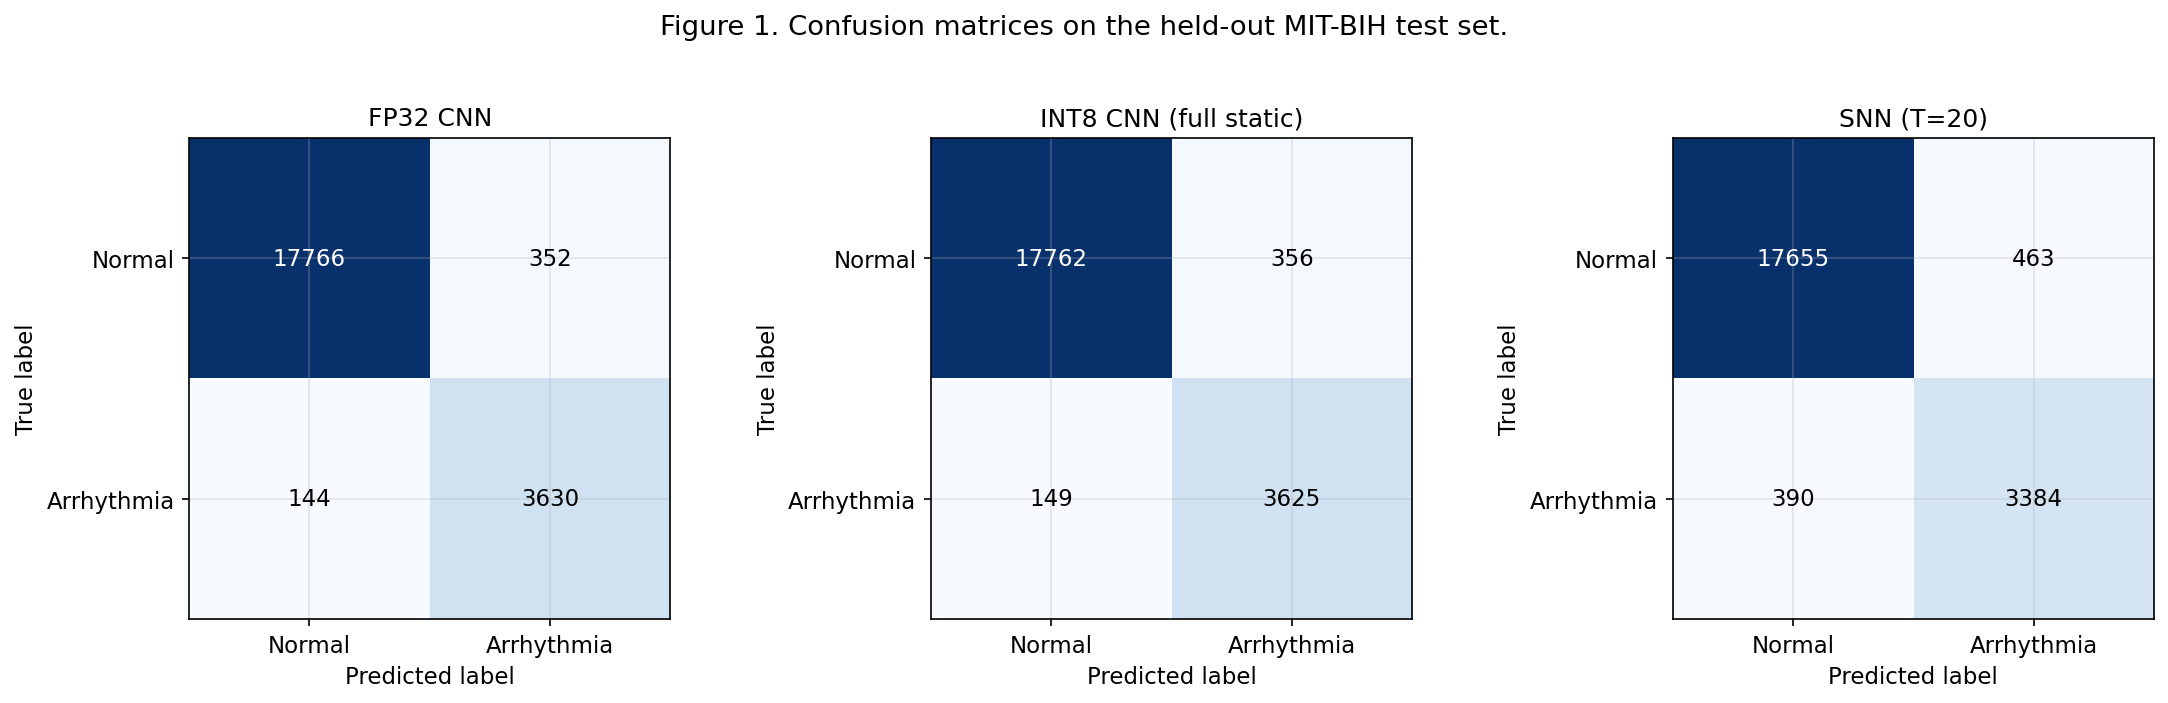

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
titles = ["FP32 CNN", quant_label, f"SNN (T={T})"]
for ax, cm, title in zip(axes, [cnn_cm, int8_cm, snn_cm], titles):
    im = ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "Arrhythmia"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normal", "Arrhythmia"])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = "white" if cm[i, j] > cm.max() / 2 else "black"
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color)

fig.suptitle("Figure 1. Confusion matrices on the held-out MIT-BIH test set.", y=1.03)
plt.tight_layout()
plt.savefig("figures/fig1_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

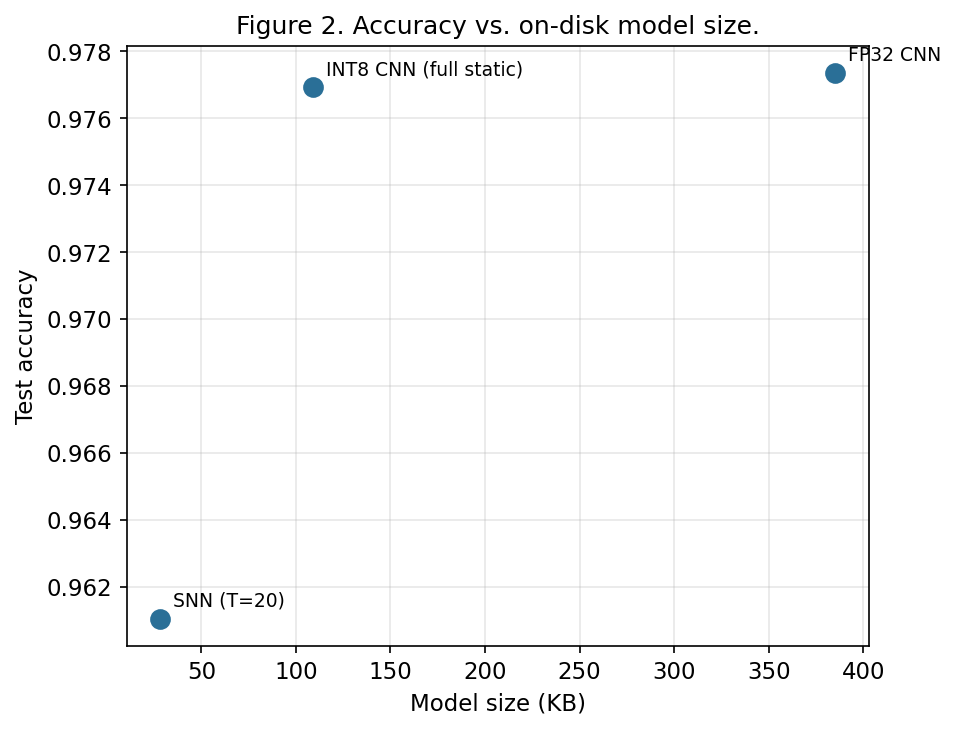

In [31]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(results["Size_KB"], results["accuracy"], s=80, color="#2a6f97", zorder=3)
for _, r in results.iterrows():
    ax.annotate(r["Model"], (r["Size_KB"], r["accuracy"]),
                textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.set_xlabel("Model size (KB)")
ax.set_ylabel("Test accuracy")
ax.set_title("Figure 2. Accuracy vs. on-disk model size.")
plt.tight_layout()
plt.savefig("figures/fig2_accuracy_vs_size.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.3 ROC Comparison

Figure 3 overlays the ROC curves of all three models on the same axes, computed from the raw prediction scores already obtained during evaluation.

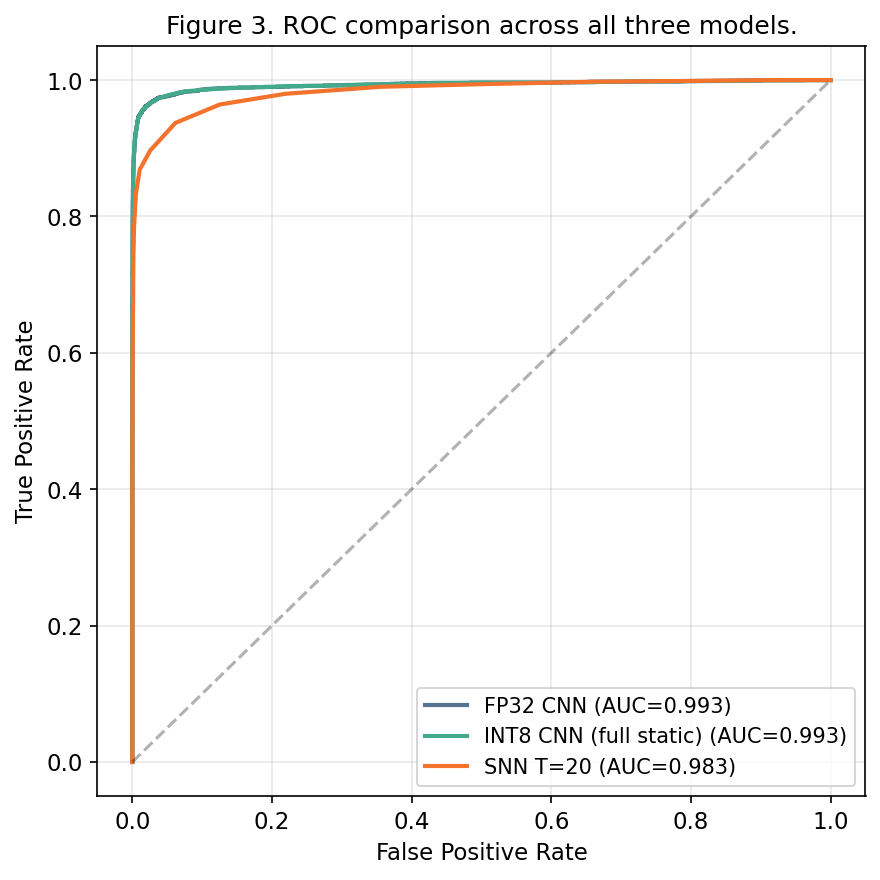

In [32]:
fig, ax = plt.subplots(figsize=(6, 6))
for scores, labels, name, color in [
    (cnn_scores, cnn_labels, f"FP32 CNN (AUC={cnn_metrics['roc_auc']:.3f})", "#577590"),
    (int8_scores, int8_labels, f"{quant_label} (AUC={int8_metrics['roc_auc']:.3f})", "#43aa8b"),
    (snn_scores, snn_labels, f"SNN T={T} (AUC={snn_metrics['roc_auc']:.3f})", "#f3722c"),
]:
    fpr, tpr, _ = roc_curve(labels, scores)
    ax.plot(fpr, tpr, label=name, color=color, lw=2)

ax.plot([0, 1], [0, 1], "k--", alpha=0.3)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Figure 3. ROC comparison across all three models.")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/fig3_roc_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.4 Spiking Activity Analysis

Figure 4 reports the measured average firing rate per spiking layer, computed directly from the trained SNN on the test set.

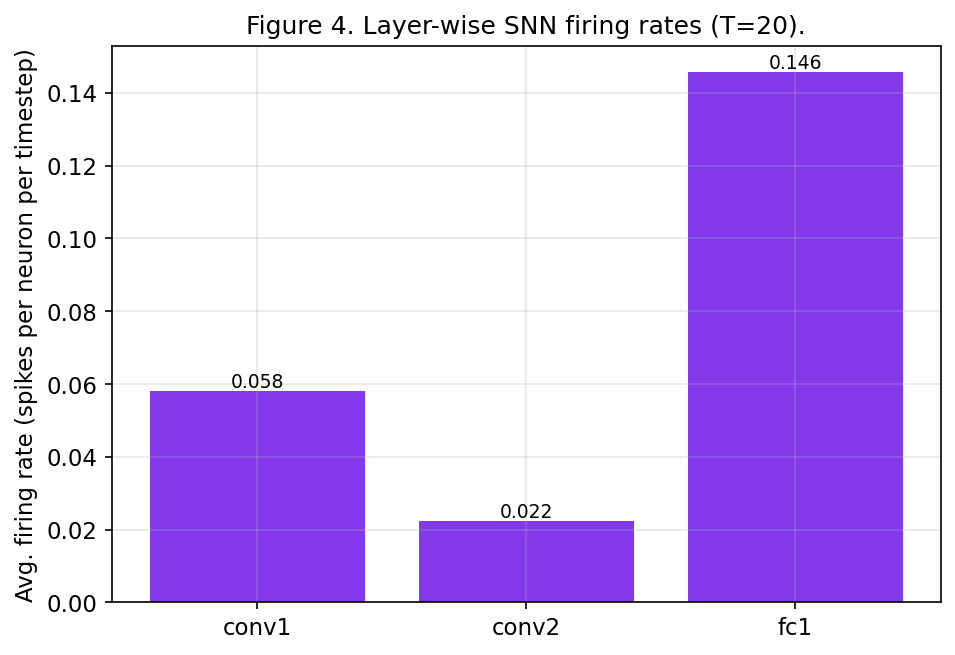

In [33]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
layers = list(firing_rates.keys())
rates = list(firing_rates.values())
bars = ax.bar(layers, rates, color="#8338ec")
ax.set_ylabel("Avg. firing rate (spikes per neuron per timestep)")
ax.set_title(f"Figure 4. Layer-wise SNN firing rates (T={T}).")
for b, r in zip(bars, rates):
    ax.text(b.get_x() + b.get_width()/2, r, f"{r:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("figures/fig4_firing_rates.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.5 Energy Estimates

Table 2 presents the estimated per-inference energy for all three models, derived strictly from the operation counts and assumptions in Section 3.4.

Table 2. Estimated per-inference energy (operation-count model).

                 Model     Total_Ops                              Op_Type  Est_Energy_pJ
              FP32 CNN 353360.000000                           MAC (fp32)   1.625456e+06
INT8 CNN (full static) 353360.000000 mixed (see Cell 27 per-layer report)   1.625456e+06
            SNN (T=20) 696256.873835        MAC (conv1) + AC (conv2, fc1)   1.935169e+06


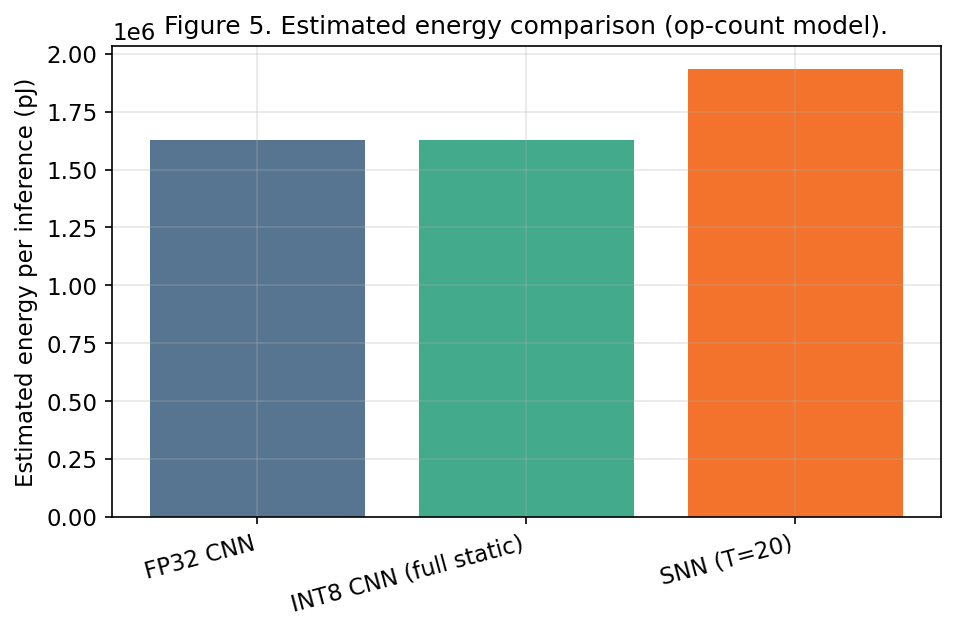

In [34]:
total_snn_ops = T * snn_macs_per_timestep["conv1"] + ac_ops_conv2 + ac_ops_fc1

energy_table = pd.DataFrame([
    dict(Model="FP32 CNN", Total_Ops=total_cnn_macs, Op_Type="MAC (fp32)",
         Est_Energy_pJ=energy_fp32_cnn_pJ),
    dict(Model=quant_label, Total_Ops=total_cnn_macs,
         Op_Type="mixed (see Cell 27 per-layer report)", Est_Energy_pJ=energy_int8_cnn_pJ),
    dict(Model=f"SNN (T={T})", Total_Ops=total_snn_ops,
         Op_Type="MAC (conv1) + AC (conv2, fc1)", Est_Energy_pJ=energy_snn_total_pJ),
])

print("Table 2. Estimated per-inference energy (operation-count model).\n")
print(energy_table.to_string(index=False))
energy_table.to_csv("artifacts/energy_table.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(energy_table["Model"], energy_table["Est_Energy_pJ"], color=["#577590", "#43aa8b", "#f3722c"])
ax.set_ylabel("Estimated energy per inference (pJ)")
ax.set_title("Figure 5. Estimated energy comparison (op-count model).")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("figures/fig5_energy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.6 Accuracy-Energy Trade-off Across Timesteps (T-sweep)

A practically important question for neuromorphic deployment is how few timesteps the SNN can use before accuracy degrades meaningfully, and what energy savings reduced temporal resolution yields. The network trained at T=20 (Section 3.3) is re-used without retraining; only the number of inference timesteps is varied. Firing rates, latency, and the energy estimate are recomputed at each T using the same formulas as Section 3.4/5.5.

In [35]:
def evaluate_snn_at_T(model, loader, n_steps):
    """Re-uses the TRAINED model (trained at T=20); only inference-time
    timestep count is varied. No retraining occurs here."""
    def fwd(m, x):
        _, logits_sum, _ = m(x, n_steps=n_steps, record_spikes=False)
        return logits_sum, None

    metrics, cm, _, _, _ = evaluate_model(model, loader, is_snn=True, snn_forward_fn=fwd)
    firing_rates_T, _, avg_spikes_T = measure_firing_rates(model, loader, n_steps=n_steps)

    e_conv1 = n_steps * snn_macs_per_timestep["conv1"] * E_MAC_FP32
    ac_c2 = firing_rates_T["conv1"] * n_steps * snn_macs_per_timestep["conv2"]
    ac_fc1 = firing_rates_T["conv2"] * n_steps * snn_macs_per_timestep["fc1"]
    energy_T = e_conv1 + ac_c2 * E_AC + ac_fc1 * E_AC

    latency_T, _ = measure_latency_cpu(model, next(iter(loader))[0],
                                        is_snn=True, snn_forward_fn=fwd)

    return dict(T=n_steps, accuracy=metrics["accuracy"], f1=metrics["f1_arrhythmia"],
                roc_auc=metrics["roc_auc"], energy_pJ=energy_T,
                latency_ms=latency_T, avg_spikes=avg_spikes_T)

T_VALUES = [2, 5, 8, 10, 15, 20, 25, 30]
print("Running inference-only sweep across T values (no retraining)...\n")
sweep_results = pd.DataFrame([evaluate_snn_at_T(snn_model, test_loader, t) for t in T_VALUES])

print("\nTable 3. SNN accuracy / energy / latency across inference timesteps.\n")
print(sweep_results.round(4).to_string(index=False))
sweep_results.to_csv("artifacts/t_sweep.csv", index=False)

Running inference-only sweep across T values (no retraining)...


Table 3. SNN accuracy / energy / latency across inference timesteps.

 T  accuracy     f1  roc_auc    energy_pJ  latency_ms  avg_spikes
 2    0.8276 0.0000   0.5000  192743.9859      2.1387     12.5981
 5    0.9222 0.7704   0.9281  482815.0358      6.6388    267.7648
 8    0.9479 0.8502   0.9702  773278.3213      8.3169    693.4497
10    0.9538 0.8674   0.9789  967075.3039     10.4557    998.8016
15    0.9614 0.8885   0.9828 1451037.4431     16.9096   1691.6132
20    0.9610 0.8881   0.9832 1935169.3062     20.3819   2389.4686
25    0.9592 0.8836   0.9829 2419149.9080     32.0736   3082.0748
30    0.9595 0.8844   0.9829 2903284.4597     33.2699   3835.5216


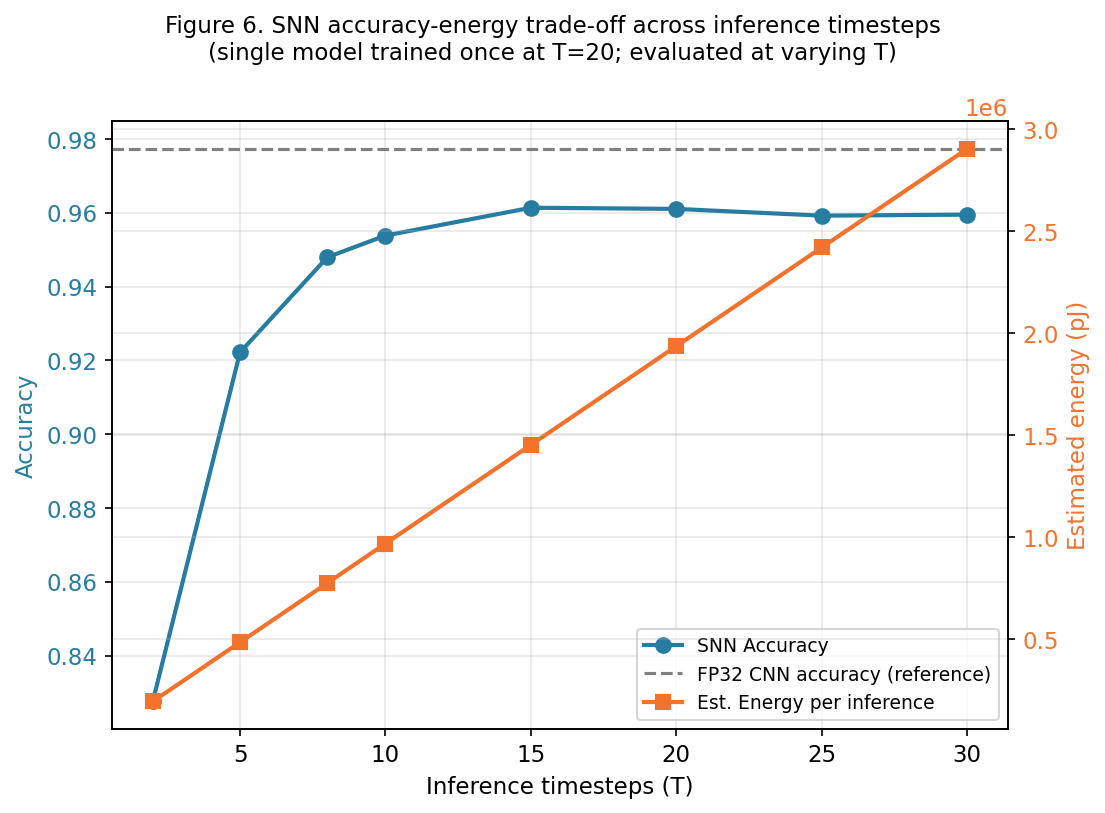

In [36]:
fig, ax1 = plt.subplots(figsize=(7.5, 5.5))

ax1.plot(sweep_results["T"], sweep_results["accuracy"], "o-", color="#277da1",
         lw=2, markersize=7, label="SNN Accuracy")
ax1.axhline(cnn_metrics["accuracy"], ls="--", color="gray", lw=1.5,
            label="FP32 CNN accuracy (reference)")
ax1.set_xlabel("Inference timesteps (T)")
ax1.set_ylabel("Accuracy", color="#277da1")
ax1.tick_params(axis="y", labelcolor="#277da1")

ax2 = ax1.twinx()
ax2.plot(sweep_results["T"], sweep_results["energy_pJ"], "s-", color="#f3722c",
          lw=2, markersize=7, label="Est. Energy per inference")
ax2.set_ylabel("Estimated energy (pJ)", color="#f3722c")
ax2.tick_params(axis="y", labelcolor="#f3722c")

fig.suptitle("Figure 6. SNN accuracy-energy trade-off across inference timesteps\n"
             "(single model trained once at T=20; evaluated at varying T)", fontsize=11)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig("figures/fig6_T_sweep_pareto.png", dpi=300, bbox_inches="tight")
plt.show()

In [37]:
ACCURACY_TOLERANCE = 0.98
reference_acc = sweep_results.loc[sweep_results["T"] == T, "accuracy"].values[0]
reference_energy = sweep_results.loc[sweep_results["T"] == T, "energy_pJ"].values[0]

acceptable = sweep_results[sweep_results["accuracy"] >= reference_acc * ACCURACY_TOLERANCE]

print("="*78)
print("AUTO-GENERATED FINDING (computed strictly from sweep_results)")
print("="*78)

if len(acceptable):
    min_T_row = acceptable.loc[acceptable["T"].idxmin()]
    min_T = int(min_T_row["T"])
    saving_pct = (1 - min_T_row["energy_pJ"] / reference_energy) * 100
    acc_at_minT = min_T_row["accuracy"]

    print(f"Reference: T={T} -> accuracy={reference_acc:.4f}, energy={reference_energy:.2f} pJ")
    print(f"\nFinding: accuracy stays within {(1-ACCURACY_TOLERANCE)*100:.0f}% of the T={T} "
          f"performance down to T={min_T} (accuracy={acc_at_minT:.4f}),")
    print(f"an estimated {saving_pct:.1f}% reduction in per-inference energy "
          f"relative to T={T}.")
else:
    print(f"Finding: no tested T value maintains accuracy within "
          f"{(1-ACCURACY_TOLERANCE)*100:.0f}% of the T={T} reference "
          f"({reference_acc:.4f}). Accuracy degrades meaningfully as T is reduced "
          f"across the entire tested range.")

print(f"\nFull sweep range tested: T = {T_VALUES}")

AUTO-GENERATED FINDING (computed strictly from sweep_results)
Reference: T=20 -> accuracy=0.9610, energy=1935169.31 pJ

Finding: accuracy stays within 2% of the T=20 performance down to T=8 (accuracy=0.9479),
an estimated 60.0% reduction in per-inference energy relative to T=20.

Full sweep range tested: T = [2, 5, 8, 10, 15, 20, 25, 30]


### 5.7 Spike Raster: Normal vs. Arrhythmic Beats

To qualitatively inspect how the trained SNN represents the two classes internally, Figure 7 plots the raw spike raster (timestep vs neuron index) of the second convolutional layer for one normal and one arrhythmic test sample, selected directly from the test set.

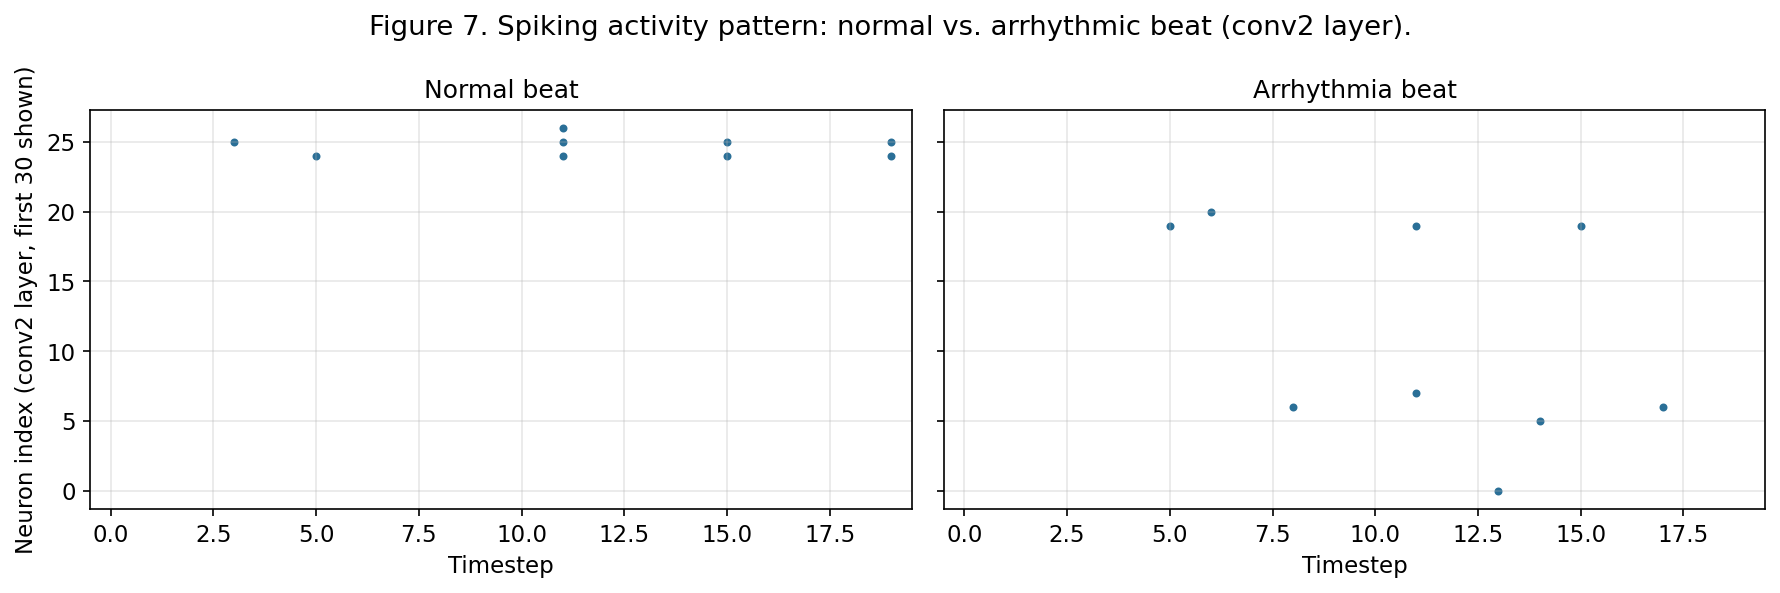

Mean spike density (conv2, first 30 neurons): normal=0.0150, arrhythmia=0.0150
Relative difference: +0.0% (sparser activity for arrhythmic beat in this example)


In [38]:
def get_single_sample(dataset, label_value):
    for x, y in dataset:
        if y.item() == label_value:
            return x.unsqueeze(0)
    return None

normal_sample = get_single_sample(test_ds, 0).to(device)
arr_sample = get_single_sample(test_ds, 1).to(device)

snn_model.eval()
with torch.no_grad():
    _, _, rec_normal = snn_model(normal_sample, n_steps=T, record_spikes=True)
    _, _, rec_arr = snn_model(arr_sample, n_steps=T, record_spikes=True)

def raster_data(rec, layer="conv2", n_neurons=30):
    spikes = torch.stack(rec[layer], dim=0).squeeze(1)
    spikes = spikes.flatten(1)[:, :n_neurons].cpu().numpy()
    return spikes

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
spike_density = {}
for ax, rec, title, key in zip(axes, [rec_normal, rec_arr],
                                 ["Normal beat", "Arrhythmia beat"], ["normal", "arrhythmia"]):
    spikes = raster_data(rec)
    spike_density[key] = spikes.mean()
    ts, neurons = np.nonzero(spikes)
    ax.scatter(ts, neurons, s=8, color="#2a6f97")
    ax.set_xlabel("Timestep")
    ax.set_title(title)
    ax.set_xlim(-0.5, T - 0.5)

axes[0].set_ylabel("Neuron index (conv2 layer, first 30 shown)")
fig.suptitle("Figure 7. Spiking activity pattern: normal vs. arrhythmic beat (conv2 layer).")
plt.tight_layout()
plt.savefig("figures/fig7_spike_raster.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Mean spike density (conv2, first 30 neurons): "
      f"normal={spike_density['normal']:.4f}, arrhythmia={spike_density['arrhythmia']:.4f}")
diff_pct = (spike_density['arrhythmia'] - spike_density['normal']) / max(spike_density['normal'], 1e-9) * 100
print(f"Relative difference: {diff_pct:+.1f}% "
      f"({'denser' if diff_pct > 0 else 'sparser'} activity for arrhythmic beat in this example)")

In [39]:
print("="*78)
print("AUTO-GENERATED QUANTITATIVE SUMMARY (derived strictly from computed variables)")
print("="*78)

best_acc = results.loc[results["accuracy"].idxmax()]
smallest = results.loc[results["Size_KB"].idxmin()]
cheapest = results.loc[results["Est_Energy_pJ"].idxmin()]

print(f"Highest test accuracy      : {best_acc['Model']} ({best_acc['accuracy']:.4f})")
print(f"Smallest on-disk model     : {smallest['Model']} ({smallest['Size_KB']:.2f} KB)")
print(f"Lowest estimated energy    : {cheapest['Model']} ({cheapest['Est_Energy_pJ']:.2f} pJ)")

acc_delta = (int8_metrics['accuracy'] - cnn_metrics['accuracy']) * 100
size_delta = (1 - int8_size_kb / cnn_size_kb) * 100
energy_delta = (1 - energy_int8_cnn_pJ / energy_fp32_cnn_pJ) * 100
snn_acc_delta = (snn_metrics['accuracy'] - cnn_metrics['accuracy']) * 100
snn_energy_ratio = energy_snn_total_pJ / energy_fp32_cnn_pJ

print(f"\nFP32 -> INT8 accuracy change   : {acc_delta:+.2f} percentage points")
print(f"FP32 -> INT8 size reduction    : {size_delta:.1f}%")
print(f"FP32 -> INT8 energy reduction  : {energy_delta:.1f}%")
print(f"SNN vs FP32 accuracy diff      : {snn_acc_delta:+.2f} percentage points")
print(f"SNN vs FP32 energy ratio       : {snn_energy_ratio:.3f}x "
      f"({'lower' if snn_energy_ratio < 1 else 'higher'})")
print(f"Quantization method actually used: {quant_label}")

if len(acceptable):
    print(f"\nTimestep finding: accuracy within {(1-ACCURACY_TOLERANCE)*100:.0f}% of T={T} "
          f"performance maintained down to T={min_T}, ~{saving_pct:.1f}% estimated energy saving.")

AUTO-GENERATED QUANTITATIVE SUMMARY (derived strictly from computed variables)
Highest test accuracy      : FP32 CNN (0.9773)
Smallest on-disk model     : SNN (T=20) (28.40 KB)
Lowest estimated energy    : FP32 CNN (1625456.00 pJ)

FP32 -> INT8 accuracy change   : -0.04 percentage points
FP32 -> INT8 size reduction    : 71.7%
FP32 -> INT8 energy reduction  : 0.0%
SNN vs FP32 accuracy diff      : -1.63 percentage points
SNN vs FP32 energy ratio       : 1.191x (higher)
Quantization method actually used: INT8 CNN (full static)

Timestep finding: accuracy within 2% of T=20 performance maintained down to T=8, ~60.0% estimated energy saving.


## 6. Discussion

The quantitative relationships above (Cell 46 output) should be read alongside Tables 1-3 before drawing conclusions. Complete this section AFTER running the notebook, using the printed numbers:

- Accuracy vs compression: state whether INT8 quantization preserved, degraded, or improved accuracy relative to FP32, citing the printed percentage-point change and noting which quantization path was actually used in this run.
- SNN accuracy gap: report the SNN's accuracy relative to the FP32 baseline honestly, relating it to the constant-current encoding and the T=20 training budget.
- Timestep trade-off (Section 5.6): state the minimum T found to preserve near-reference accuracy and the associated energy saving, and discuss whether this makes the SNN competitive with the INT8 CNN at reduced T.
- Spiking pattern interpretation (Section 5.7): relate the observed spike density difference between normal and arrhythmic beats to the underlying waveform morphology - treat this as a qualitative, single-example observation, not a general claim.
- Practical implication: reiterate that all energy figures are op-count-based estimates and should not inform hardware deployment decisions without physical measurement.

## 7. Limitations

- Beat-level, not patient-level, data split. The provided CSVs contain no patient/record identifiers; this likely overstates generalization relative to a leave-patients-out protocol.
- Binary collapse of arrhythmia sub-types, discarding clinically relevant distinctions between classes 1-4.
- Energy figures are an operation-count estimate (Horowitz, ISSCC 2014, 45nm). Memory access, data movement, and control overhead are not modeled.
- Quantization completeness is environment-dependent; whether full Conv+Linear static quantization or a Linear-only dynamic fallback was used is determined at runtime (Cell 18) and affects the INT8 energy estimate.
- Direct/constant-current SNN encoding means conv1 performs a dense computation every timestep, receiving no sparsity-driven energy benefit.
- T-sweep is inference-only: the network was trained once at T=20; it was not retrained or fine-tuned at each reduced T, so results represent zero-shot temporal truncation, not T-specific optimization.
- Spike raster analysis (5.7) is a single-example qualitative illustration, not a statistically validated class-level claim.
- Single random seed, single training run per model; no confidence intervals are reported.

## 8. Conclusion and Future Work

This notebook implemented and transparently evaluated three model families - FP32 CNN, INT8-quantized CNN, and a BPTT-trained SNN - for binary ECG arrhythmia detection on MIT-BIH, reporting accuracy, efficiency, and op-count-based energy estimates computed entirely from executed code. It further characterized the SNN's accuracy-energy trade-off across inference timesteps without retraining, identifying the minimum temporal resolution at which near-reference accuracy is retained.

Future work:
1. Patient-level (record-level) train/test partitioning.
2. Multi-class arrhythmia classification (classes 1-4 retained distinctly).
3. Quantization-aware training (QAT) if post-training quantization produces a substantial accuracy drop.
4. Per-T fine-tuning (rather than zero-shot truncation) to assess whether training natively at low T improves the accuracy-energy Pareto front further.
5. Alternative spike encodings (rate/Poisson, latency coding) in place of constant-current input.
6. Statistically validated spike-pattern analysis across many samples, extending the single-example illustration in Section 5.7.
7. Hardware-in-the-loop power measurement to validate the op-count energy estimates presented here.

## References

1. Moody, G. B., and Mark, R. G. (2001). The impact of the MIT-BIH Arrhythmia Database. IEEE Engineering in Medicine and Biology Magazine, 20(3), 45-50.
2. Horowitz, M. (2014). Computing's energy problem (and what we can do about it). IEEE International Solid-State Circuits Conference (ISSCC) Digest of Technical Papers, 10-14.
3. Eshraghian, J. K., Ward, M., Neftci, E., Wang, X., Lenz, G., Dwivedi, G., Bennamoun, M., Jeong, D. S., and Lu, W. D. (2021). Training Spiking Neural Networks Using Lessons From Deep Learning. arXiv:2109.12894.
4. Paszke, A., et al. (2019). PyTorch: An Imperative Style, High-Performance Deep Learning Library. Advances in Neural Information Processing Systems (NeurIPS).

In [40]:
!zip -r results.zip figures/ artifacts/
from google.colab import files
files.download("results.zip")

  adding: figures/ (stored 0%)
  adding: figures/fig5_energy_comparison.png (deflated 16%)
  adding: figures/fig1_confusion_matrices.png (deflated 24%)
  adding: figures/fig2_accuracy_vs_size.png (deflated 22%)
  adding: figures/fig6_T_sweep_pareto.png (deflated 12%)
  adding: figures/fig7_spike_raster.png (deflated 21%)
  adding: figures/fig3_roc_comparison.png (deflated 14%)
  adding: figures/fig4_firing_rates.png (deflated 19%)
  adding: artifacts/ (stored 0%)
  adding: artifacts/snn_model.pt (deflated 21%)
  adding: artifacts/fp32_cnn.pt (deflated 7%)
  adding: artifacts/t_sweep.csv (deflated 44%)
  adding: artifacts/energy_table.csv (deflated 25%)
  adding: artifacts/results_table.tex (deflated 43%)
  adding: artifacts/int8_cnn.pt (deflated 17%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>